## Mount Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Import Liabraries

In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Train-test split and cross-validation
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import fbeta_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_curve
)

# Feature importance
from sklearn.inspection import permutation_importance

# Saving model
import joblib

import warnings
warnings.filterwarnings('ignore')

# Visualization settings
sns.set_theme(style='whitegrid')

## Load Dateset

In [3]:
df_x = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Module Project/M-6/train.csv')

In [4]:
df_y = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Module Project/M-6/test.csv')

### Check Basic Infomation

In [5]:
df_x.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 136429 entries, 0 to 136428
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       136429 non-null  int64  
 1   Product ID               136429 non-null  object 
 2   Type                     136429 non-null  object 
 3   Air temperature [K]      136429 non-null  float64
 4   Process temperature [K]  136429 non-null  float64
 5   Rotational speed [rpm]   136429 non-null  int64  
 6   Torque [Nm]              136429 non-null  float64
 7   Tool wear [min]          136429 non-null  int64  
 8   Machine failure          136429 non-null  int64  
 9   TWF                      136429 non-null  int64  
 10  HDF                      136429 non-null  int64  
 11  PWF                      136429 non-null  int64  
 12  OSF                      136429 non-null  int64  
 13  RNF                      136429 non-null  int64  
dtypes: f

In [6]:
display(df_x.describe())

,id,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000,136429.000000
mean,68214.000000,299.862776,309.941070,1520.331110,40.348643,104.408901,0.015744,0.001554,0.005160,0.002397,0.003958,0.002258
std,39383.804275,1.862247,1.385173,138.736632,8.502229,63.965040,0.124486,0.039389,0.071649,0.048899,0.062789,0.047461
min,0.000000,295.300000,305.800000,1181.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,34107.000000,298.300000,308.700000,1432.000000,34.600000,48.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,68214.000000,300.000000,310.000000,1493.000000,40.400000,106.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,102321.000000,301.200000,310.900000,1580.000000,46.100000,159.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,136428.000000,304.400000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [7]:
print("Missing Values:")
print(df_x.isnull().sum())

Missing Values:
id                         0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


In [8]:
print("Duplicate Rows:", df_x.duplicated().sum())

print("Duplicate IDs:", df_x['id'].duplicated().sum())

Duplicate Rows: 0
Duplicate IDs: 0


In [9]:
print(df_x.nunique())

id                         136429
Product ID                   9976
Type                            3
Air temperature [K]            95
Process temperature [K]        81
Rotational speed [rpm]        952
Torque [Nm]                   611
Tool wear [min]               246
Machine failure                 2
TWF                             2
HDF                             2
PWF                             2
OSF                             2
RNF                             2
dtype: int64


In [10]:
print(df_x['Machine failure'].value_counts())

print("\nPercentage Distribution:")

print(
    df_x['Machine failure']
    .value_counts(normalize=True) * 100
)

Machine failure
0    134281
1      2148
Name: count, dtype: int64

Percentage Distribution:
Machine failure
0    98.425555
1     1.574445
Name: proportion, dtype: float64


## EDA

### Univariate Analysis

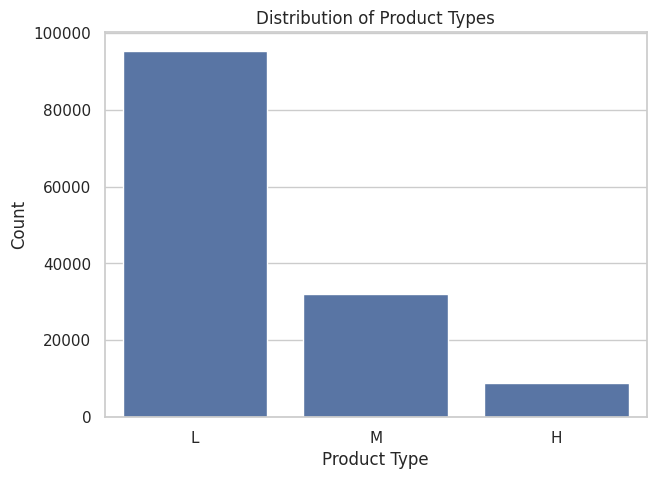

In [11]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_x,
    x='Type',
    order=df_x['Type'].value_counts().index
)

plt.title('Distribution of Product Types')
plt.xlabel('Product Type')
plt.ylabel('Count')

plt.show()

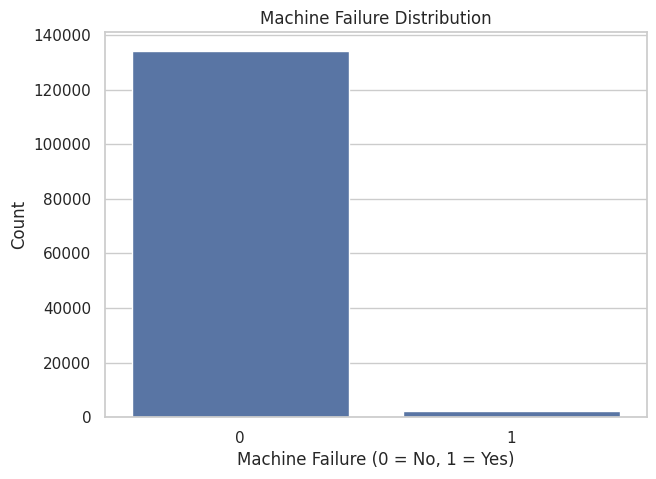

In [12]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_x,
    x='Machine failure'
)

plt.title('Machine Failure Distribution')
plt.xlabel('Machine Failure (0 = No, 1 = Yes)')
plt.ylabel('Count')

plt.show()

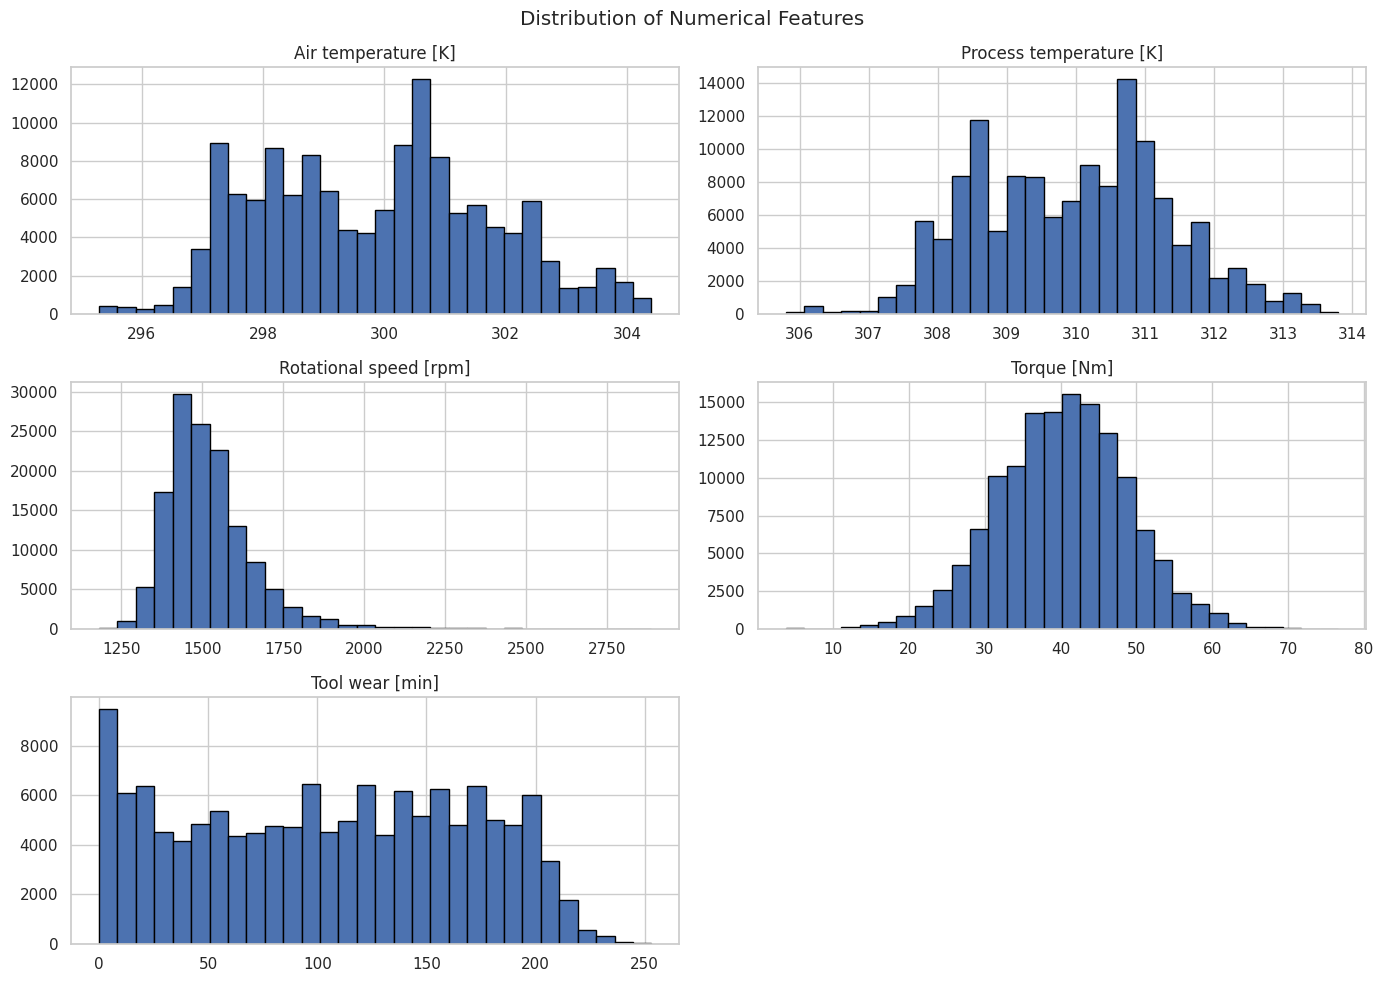

In [13]:
numerical_cols = [
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]'
]

df_x[numerical_cols].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical Features')

plt.tight_layout()

plt.show()

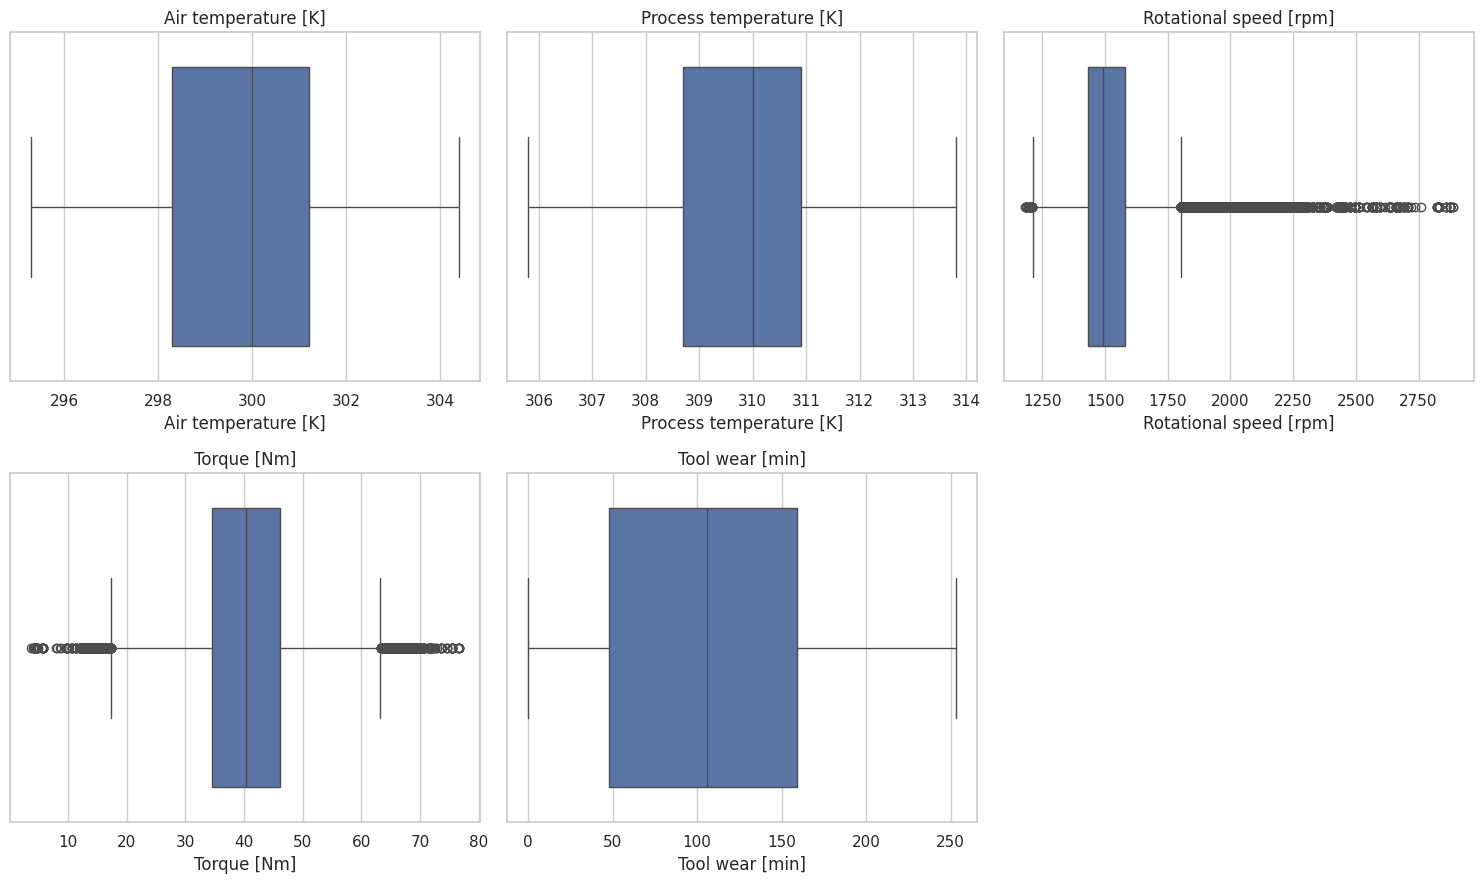

In [14]:
plt.figure(figsize=(15, 9))

for i, col in enumerate(numerical_cols, 1):

    plt.subplot(2, 3, i)

    sns.boxplot(
        x=df_x[col]
    )

    plt.title(col)

plt.tight_layout()

plt.show()

### Bivariate Analysis

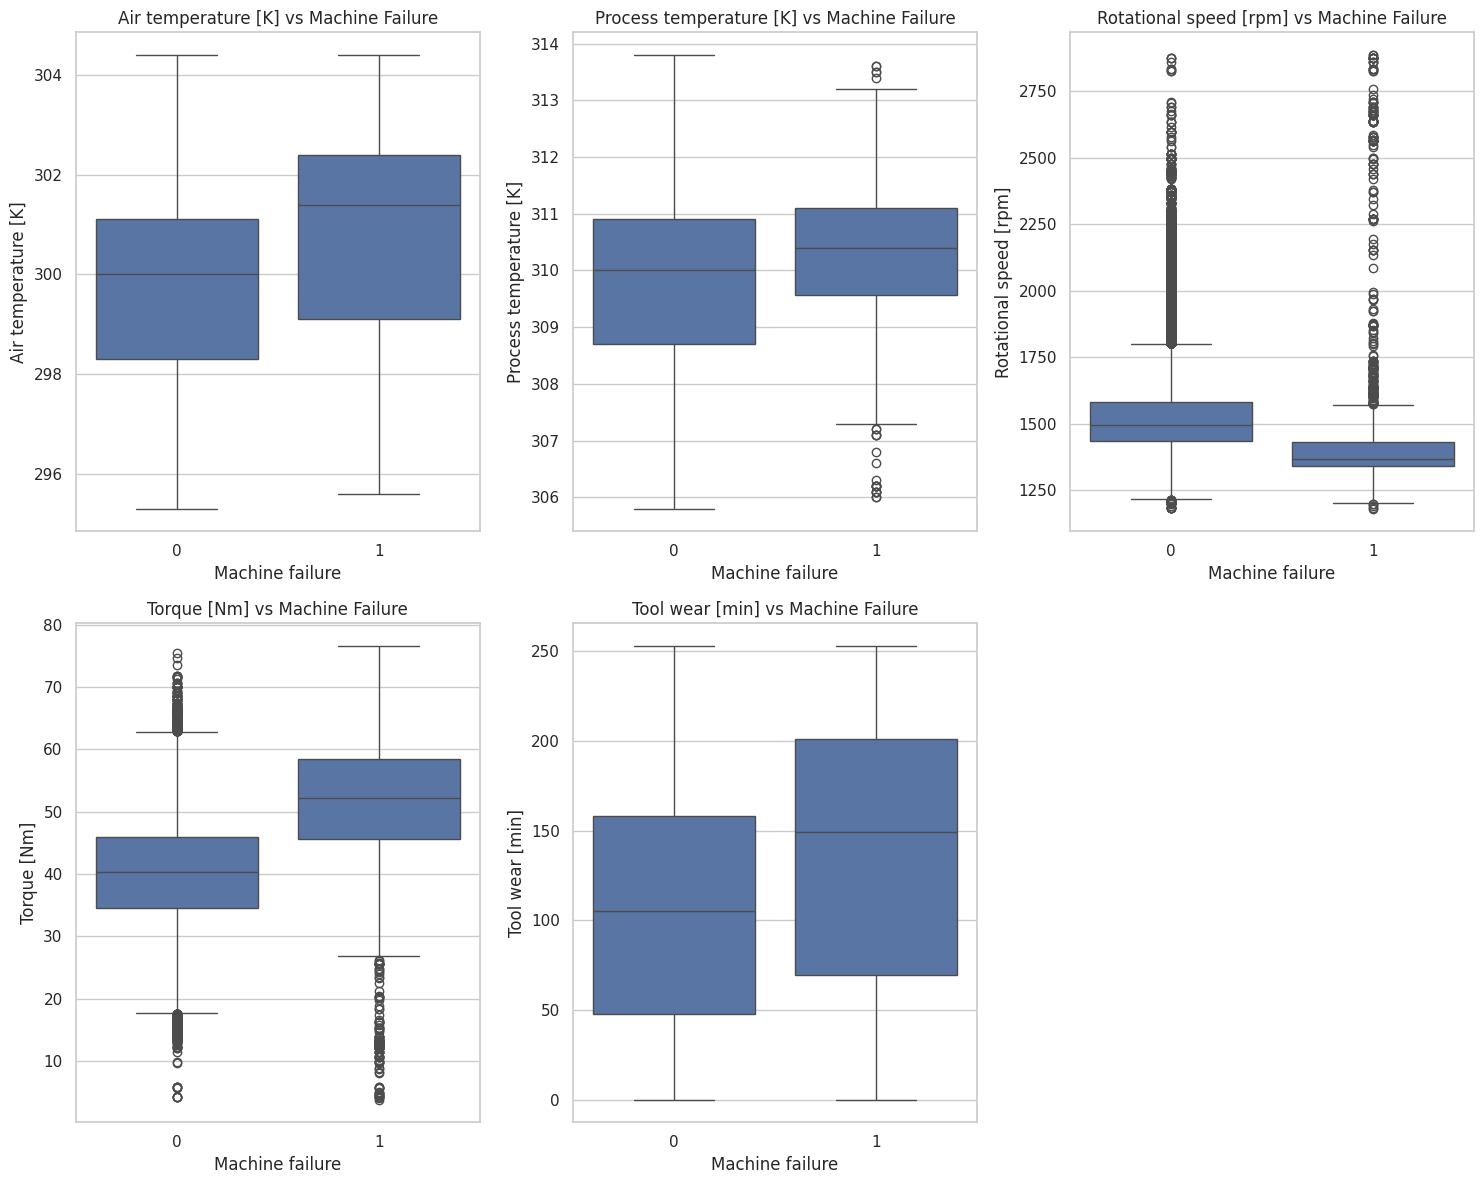

In [15]:
plt.figure(figsize=(15, 12))

for i, col in enumerate(numerical_cols, 1):

    plt.subplot(2, 3, i)

    sns.boxplot(
        data=df_x,
        x='Machine failure',
        y=col
    )

    plt.title(f'{col} vs Machine Failure')

plt.tight_layout()

plt.show()

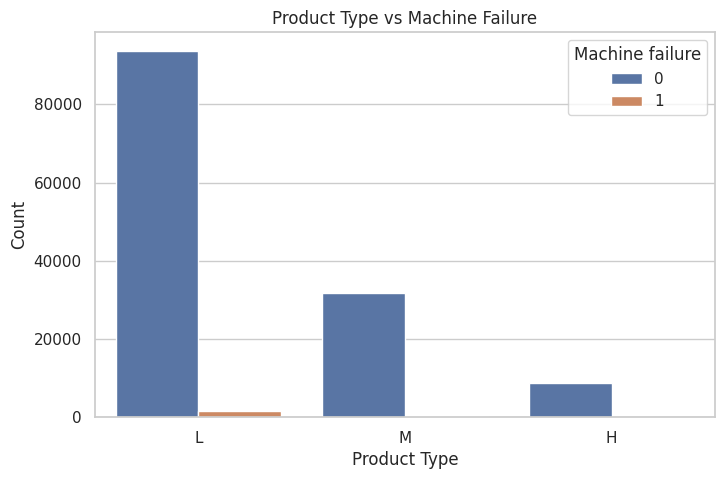

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_x,
    x='Type',
    hue='Machine failure'
)

plt.title('Product Type vs Machine Failure')
plt.xlabel('Product Type')
plt.ylabel('Count')

plt.show()

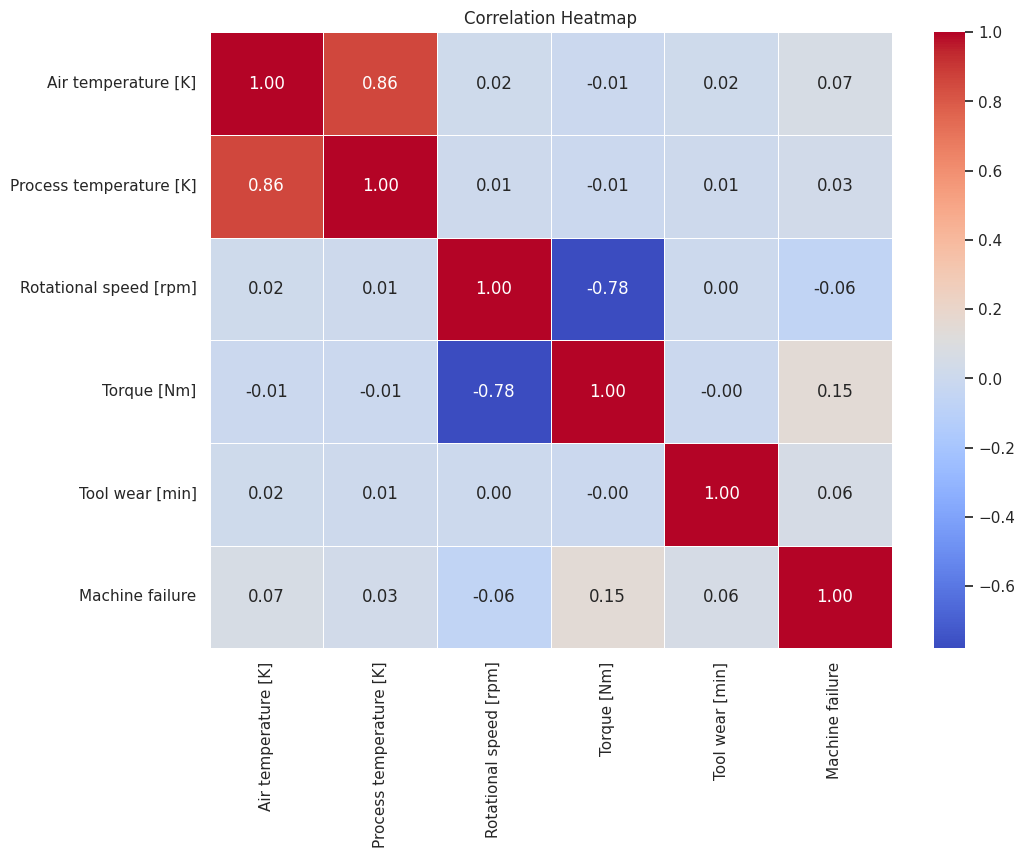

In [17]:
correlation = df_x[
    numerical_cols + ['Machine failure']
].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')

plt.show()

## Feature Engineering

In [18]:
# Temperature Difference

df_x['Temperature Difference'] = (
    df_x['Process temperature [K]'] -
    df_x['Air temperature [K]']
)


# Mechanical Power

df_x['Mechanical Power [kW]'] = (
    df_x['Torque [Nm]'] *
    df_x['Rotational speed [rpm]'] *
    2 * np.pi / 60 / 1000
)


display(
    df_x[
        [
            'Temperature Difference',
            'Mechanical Power [kW]'
        ]
    ].describe()
)

,Temperature Difference,Mechanical Power [kW]
count,136429.000000,136429.000000
mean,10.078295,6.327582
std,0.984934,0.998141
min,3.200000,0.610474
25%,9.300000,5.675779
50%,9.900000,6.310203
75%,11.000000,6.964094
max,15.000000,16.007064


## Prepare Data for Machine Learning

### Select Features and Target

In [19]:
features = [
    'Type',
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]',
    'Temperature Difference',
    'Mechanical Power [kW]'
]

X = df_x[features]

y = df_x['Machine failure']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (136429, 8)
Target Shape: (136429,)


### Train - Test Split

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Data: (109143, 8)
Testing Data: (27286, 8)

Training Target Distribution:
Machine failure
0    98.425918
1     1.574082
Name: proportion, dtype: float64

Testing Target Distribution:
Machine failure
0    98.4241
1     1.5759
Name: proportion, dtype: float64


## Data Preprocessing

In [21]:
categorical_features = [
    'Type'
]

numerical_features = [
    col for col in features
    if col not in categorical_features
]


preprocessor = ColumnTransformer(
    transformers=[

        (
            'num',
            StandardScaler(),
            numerical_features
        ),

        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        )

    ]
)

## Machine Learning Model

### Logistic Regression

In [22]:
lr_model = Pipeline([

    ('preprocessor', preprocessor),

    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=2000,
        random_state=42
    ))

])

### Random Forest

In [23]:
rf_model = Pipeline([

    ('preprocessor', preprocessor),

    ('classifier', RandomForestClassifier(
        n_estimators=400,
        max_depth=None,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
    ))

])

In [24]:
models = {
    'Logistic Regression': lr_model,
    'Random Forest': rf_model
}

### Cross-Validation

In [25]:
skf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [26]:
scoring = {

    'accuracy': 'accuracy',

    'precision': 'precision',

    'recall': 'recall',

    'f1': 'f1',

    'roc_auc': 'roc_auc',

    'pr_auc': 'average_precision'

}

In [27]:
cv_results = []

for name, model in models.items():

    print(f"Running Cross Validation: {name}")

    scores = cross_validate(

        model,

        X_train,

        y_train,

        cv=skf,

        scoring=scoring,

        return_train_score=False,

        n_jobs=1

    )

    cv_results.append({

        'Model': name,

        'Accuracy': scores['test_accuracy'].mean(),

        'Precision': scores['test_precision'].mean(),

        'Recall': scores['test_recall'].mean(),

        'F1 Score': scores['test_f1'].mean(),

        'ROC-AUC': scores['test_roc_auc'].mean(),

        'PR-AUC': scores['test_pr_auc'].mean()

    })


cv_df = pd.DataFrame(cv_results)

cv_df = cv_df.sort_values(
    by='PR-AUC',
    ascending=False
)

display(cv_df)

Running Cross Validation: Logistic Regression
Running Cross Validation: Random Forest


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
1,Random Forest,0.986495,0.598369,0.433062,0.502372,0.925354,0.446382
0,Logistic Regression,0.829123,0.068109,0.777081,0.125241,0.870736,0.288131


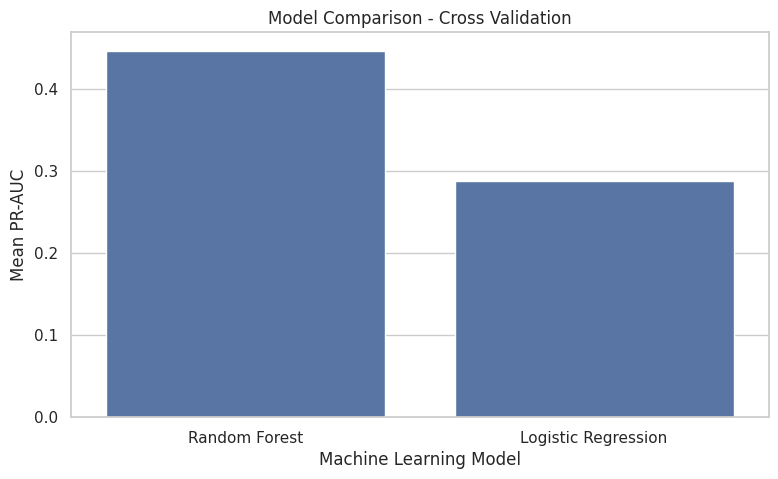

In [28]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=cv_df,
    x='Model',
    y='PR-AUC'
)

plt.title('Model Comparison - Cross Validation')
plt.xlabel('Machine Learning Model')
plt.ylabel('Mean PR-AUC')

plt.show()

### Best Model

In [29]:
best_model_name = cv_df.loc[
    cv_df['PR-AUC'].idxmax(),
    'Model'
]

best_model = models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Random Forest


In [30]:
oof_prob = cross_val_predict(

    best_model,

    X_train,

    y_train,

    cv=skf,

    method='predict_proba',

    n_jobs=1

)[:, 1]

In [31]:
precision, recall, thresholds = precision_recall_curve(
    y_train,
    oof_prob
)

f2_scores = (

    5 * precision[:-1] * recall[:-1]

    /

    (
        4 * precision[:-1] +
        recall[:-1] +
        1e-10
    )

)

best_threshold = thresholds[np.argmax(f2_scores)]

print("Best Threshold:", best_threshold)

print("Cross-Validated F2 Score:", f2_scores.max())

Best Threshold: 0.18216112609123244
Cross-Validated F2 Score: 0.5521166133916096


### Train the Best Model (On seen data)

In [32]:
best_model.fit(
    X_train,
    y_train
)

print("Final Model Training Completed!")

Final Model Training Completed!


In [33]:
# Predict probabilities

y_test_prob = best_model.predict_proba(
    X_test
)[:, 1]


# Apply optimized threshold

y_test_pred = (
    y_test_prob >= best_threshold
).astype(int)

### Model Evaluation

In [34]:
print("Best Model:", best_model_name)

print("\nAccuracy:",
      accuracy_score(y_test, y_test_pred))

print("Precision:",
      precision_score(y_test, y_test_pred, zero_division=0))

print("Recall:",
      recall_score(y_test, y_test_pred, zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_test_pred, zero_division=0))

print("F2 Score:",
      fbeta_score(y_test, y_test_pred, beta=2, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, y_test_prob))

print("PR-AUC:",
      average_precision_score(y_test, y_test_prob))

Best Model: Random Forest

Accuracy: 0.9754086344645606
Precision: 0.3428943937418514
Recall: 0.6116279069767442
F1 Score: 0.4394319131161236
F2 Score: 0.5287494973864093
ROC-AUC: 0.9141269804157921
PR-AUC: 0.41043110806094707


In [35]:
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=[
            'No Failure',
            'Failure'
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

  No Failure       0.99      0.98      0.99     26856
     Failure       0.34      0.61      0.44       430

    accuracy                           0.98     27286
   macro avg       0.67      0.80      0.71     27286
weighted avg       0.98      0.98      0.98     27286



## Model evaluation visualizations

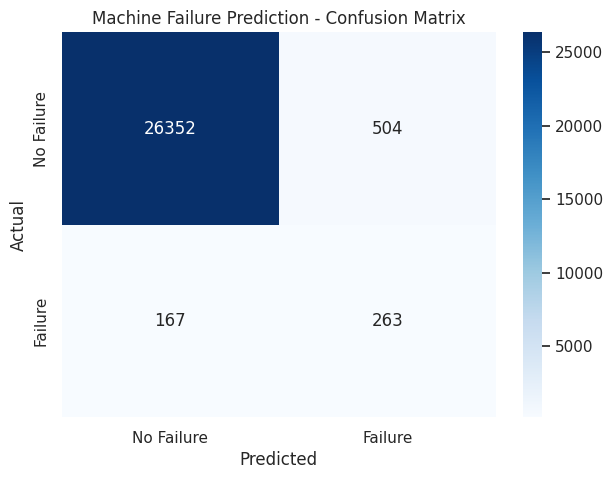

In [36]:
cm = confusion_matrix(
    y_test,
    y_test_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Failure', 'Failure'],
    yticklabels=['No Failure', 'Failure']
)

plt.title('Machine Failure Prediction - Confusion Matrix')

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

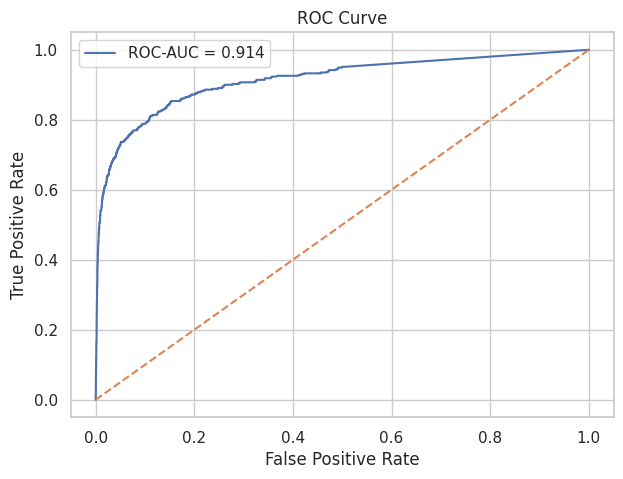

In [37]:
fpr, tpr, thresholds_roc = roc_curve(
    y_test,
    y_test_prob
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'ROC-AUC = {roc_auc_score(y_test, y_test_prob):.3f}'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curve')

plt.legend()

plt.show()

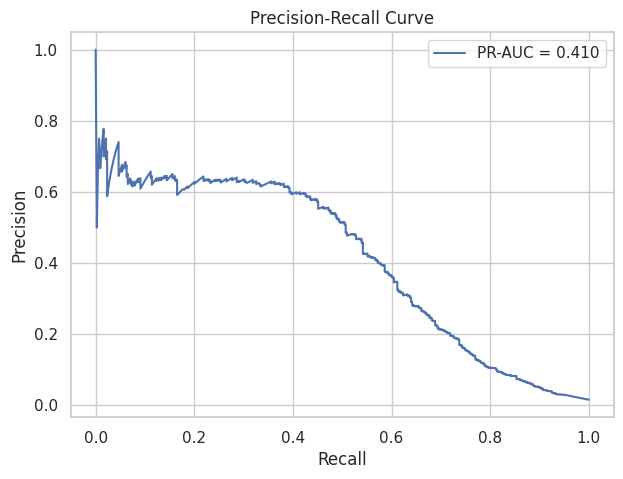

In [38]:
precision, recall, thresholds_pr = precision_recall_curve(
    y_test,
    y_test_prob
)

plt.figure(figsize=(7, 5))

plt.plot(
    recall,
    precision,
    label=f'PR-AUC = {average_precision_score(y_test, y_test_prob):.3f}'
)

plt.xlabel('Recall')
plt.ylabel('Precision')

plt.title('Precision-Recall Curve')

plt.legend()

plt.show()

### Feature Importance

In [39]:
importance = permutation_importance(

    best_model,

    X_test,

    y_test,

    scoring='average_precision',

    n_repeats=5,

    random_state=42,

    n_jobs=1

)


importance_df = pd.DataFrame({

    'Feature': features,

    'Importance': importance.importances_mean

})


importance_df = importance_df.sort_values(

    by='Importance',

    ascending=False

)


display(importance_df)

,Feature,Importance
3,Rotational speed [rpm],0.209944
6,Temperature Difference,0.126554
4,Torque [Nm],0.100104
5,Tool wear [min],0.060233
1,Air temperature [K],0.060162
7,Mechanical Power [kW],0.042461
2,Process temperature [K],0.003124
0,Type,0.000559


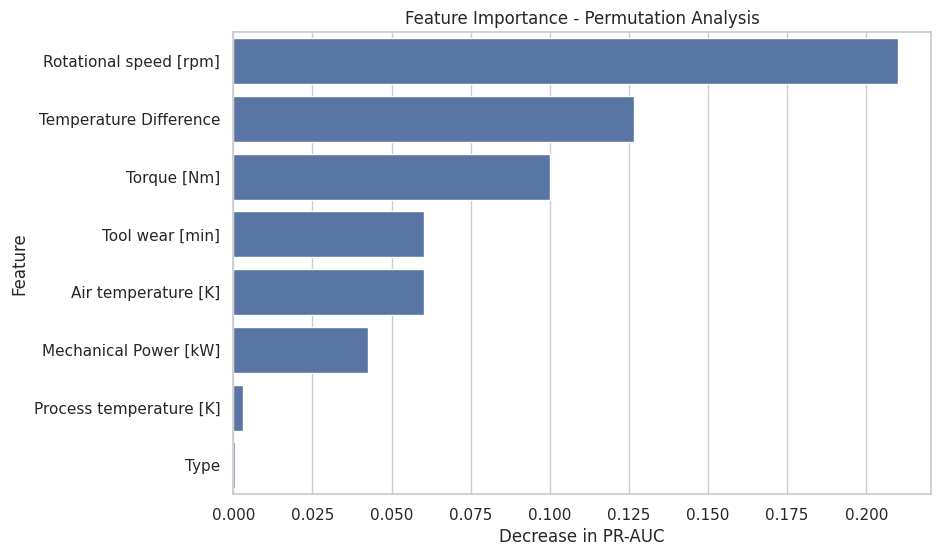

In [40]:
plt.figure(figsize=(9, 6))

sns.barplot(

    data=importance_df,

    x='Importance',

    y='Feature'

)

plt.title('Feature Importance - Permutation Analysis')

plt.xlabel('Decrease in PR-AUC')

plt.ylabel('Feature')

plt.show()

## Model Testing on Unseen Data

### Creat New Features

In [41]:
# Temperature Difference

df_y['Temperature Difference'] = (
    df_y['Process temperature [K]'] -
    df_y['Air temperature [K]']
)


# Mechanical Power

df_y['Mechanical Power [kW]'] = (
    df_y['Torque [Nm]'] *
    df_y['Rotational speed [rpm]'] *
    2 * np.pi / 60 / 1000
)


display(
    df_y[
        [
            'Temperature Difference',
            'Mechanical Power [kW]'
        ]
    ].describe()
)

,Temperature Difference,Mechanical Power [kW]
count,90954.000000,90954.000000
mean,10.079882,6.325653
std,0.981978,0.998977
min,3.600000,0.718378
25%,9.300000,5.674722
50%,9.900000,6.313659
75%,11.000000,6.964801
max,15.600000,18.531522


### Predict

In [42]:
df_y_predictions = model.predict(df_y)

df_y_prob = best_model.predict_proba(
    df_y
)[:, 1]

### Save as DataFrame

In [43]:
results = pd.DataFrame({
    "id": df_y["id"],
    "Machine failure": df_y_predictions,
    "Failure probability": df_y_prob
})

print("\nTest predictions saved successfully!")
print(results.head())


Test predictions saved successfully!
       id  Machine failure  Failure probability
0  136429                0             0.000000
1  136430                0             0.116418
2  136431                0             0.000000
3  136432                0             0.000000
4  136433                0             0.007331


### Save in Drive

In [44]:

results.to_csv(
    "/content/drive/MyDrive/Colab Notebooks/Module Project/M-6/ Machine_failure_predictions.csv",
    index=False
)

## Conclusion

### **1. Overall Model Performance**

* **High Discriminative Ability:** The **ROC-AUC score of 0.914** indicates that the model has an excellent overall ability to distinguish between machines that will fail and those that will operate normally.
* **High Accuracy:** With an overall accuracy of approximately **97.5%** (26,615 correct predictions out of 27,286 total samples), the model appears exceptionally accurate at a glance.

---

### **2. Performance on the Minority Class (Failures)**

Because machine failure datasets are typically heavily imbalanced (with "No Failure" vastly outnumbering "Failure" cases), looking solely at accuracy can be misleading. A deeper look at the confusion matrix and Precision-Recall curve reveals specific trade-offs:

* **Recall (Sensitivity) $\approx$ 61.2%:** The model successfully identifies 263 out of 430 actual failures, meaning it catches about 61% of impending failures. However, it misses **167 actual failures (False Negatives)**.
* **Precision $\approx$ 34.3%:** Out of all instances predicted as failures (767 total predictions), only 263 were correct. This results in **504 False Positives (False Alarms)**.
* **PR-AUC = 0.410:** This lower metric underscores the challenge the model faces in maintaining high precision as recall increases, which is typical in severely imbalanced classification tasks.

---

### **3. Practical & Operational Implications**

* **Risk of Missed Failures (False Negatives):** Missing 167 failures could lead to unexpected downtime, costly emergency repairs, or safety hazards if deployed in a live industrial environment.
* **Alarm Fatigue (False Positives):** Generating 504 false alarms means maintenance teams might frequently inspect healthy machines, leading to wasted labor and maintenance costs.

---

### **4. Recommendations**

* **Threshold Tuning:** Adjusting the classification decision threshold can help optimize the balance between precision and recall depending on operational priorities (e.g., lowering the threshold to catch more failures if downtime is costlier than false alarms).
* **Advanced Imbalance Handling:** Techniques such as cost-sensitive learning, SMOTE (Synthetic Minority Over-sampling Technique), or adjusting class weights during training can improve the Precision-Recall trade-off (PR-AUC).